# 07 · Dynamic security assessment with interpretable decision trees
**Level 3 · Predictive analytics (supervised)** &nbsp;|&nbsp; Course link: *Module 4 – dynamic security assessment with
classification and decision trees*

A transmission system operator must make sure that if the **largest power plant or interconnector trips**, the grid
frequency does not fall so low that load-shedding relays act or generators disconnect (blackout risk). As wind and
solar replace synchronous machines, the system has **less inertia** and frequency falls faster.

Simulating every possible operating state in real time is too slow, so the workflow is:
1. **offline:** simulate thousands of operating points and label each one *secure* / *insecure*;
2. **train** a classifier on these labelled snapshots;
3. **online:** evaluate the live state in microseconds with the classifier.

Control-room operators must understand *why* the system is flagged, so we use a **decision tree**: a white-box model.

In [1]:
import warnings, time
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, accuracy_score, precision_score, recall_score
from energy_ai import style, set_seed
style(); set_seed(0)

## 1. The physics: frequency after losing an infeed
With $E_{kin}=H\,S_{sync}$ the kinetic energy stored in synchronous machines [MWs], the system frequency obeys
$$\frac{2E_{kin}}{f_0}\,\frac{d\Delta f}{dt} = P_{res}(t) + P_{FFR}(t) - P_{loss} - D\,P_{load}\,\frac{\Delta f}{f_0}$$
* $P_{res}$: primary reserves from conventional plants, ramping with time constant 4 s up to $R_{max}$ (full at −0.5 Hz);
* $P_{FFR}$: **fast frequency response** from batteries, triggered at $\Delta f=-0.2$ Hz (full at −0.25 Hz), delivered within ~0.5 s;
* the renewable share reduces $S_{sync}$, hence the inertia.

**Security criteria** (GB-style): frequency nadir ≥ **49.2 Hz** and rate of change of frequency (RoCoF) ≤ **0.5 Hz/s**.

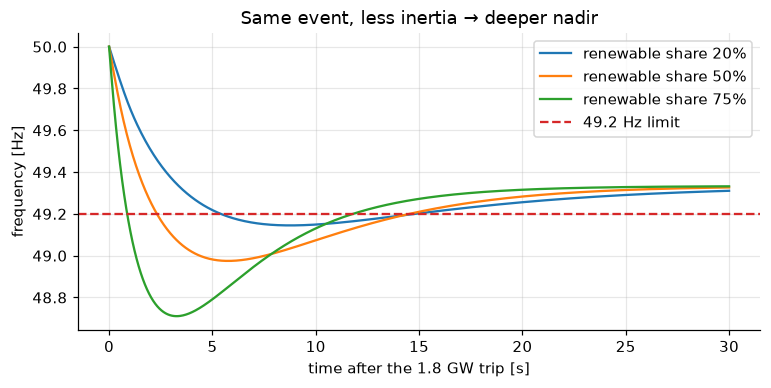

In [2]:
F0 = 50.0

def simulate(load_mw, res_share, H, loss_mw, reserve_mw, ffr_mw, T=30.0, return_traj=False):
    s_sync = load_mw * (1 - res_share) / 0.85            # MVA of synchronous machines online
    ekin = H * s_sync                                      # MWs
    D = 0.025 * 50                                         # load damping: 2.5 % of load per Hz → per unit on f0
    def rhs(t, x):
        df, pr, pf = x
        r_target = reserve_mw * np.clip(-df / 0.5, 0, 1)
        f_target = ffr_mw * np.clip((-df - 0.2) / 0.05, 0, 1)
        return [F0 / (2 * ekin) * (pr + pf - loss_mw - D * load_mw * df / F0),
                (r_target - pr) / 4.0, (f_target - pf) / 0.5]
    sol = solve_ivp(rhs, (0, T), [0, 0, 0], max_step=0.05, rtol=1e-6)
    f = F0 + sol.y[0]
    rocof = np.abs(np.gradient(f, sol.t))[sol.t <= 0.5].max()
    if return_traj:
        return sol.t, f
    return f.min(), rocof

fig, ax = plt.subplots(figsize=(8, 3.5))
for res, H in ((0.2, 5), (0.5, 4.5), (0.75, 4)):
    t, f = simulate(30000, res, H, 1800, 1000, 300, return_traj=True)
    ax.plot(t, f, label=f"renewable share {res:.0%}")
ax.axhline(49.2, color="tab:red", ls="--", label="49.2 Hz limit")
ax.set(xlabel="time after the 1.8 GW trip [s]", ylabel="frequency [Hz]", title="Same event, less inertia → deeper nadir")
ax.legend(); plt.show()

## 2. Offline database: 6 000 simulated operating points

In [3]:
rng = np.random.default_rng(1)
N = 6000
ops = pd.DataFrame({
    "load_mw": rng.uniform(18000, 50000, N),
    "renewable_share": rng.uniform(0.0, 0.85, N),
    "H_s": rng.uniform(3.0, 6.0, N),
    "largest_loss_mw": rng.choice([1000, 1320, 1400, 1800], N),
    "primary_reserve_mw": rng.uniform(400, 2000, N),
    "ffr_mw": rng.uniform(0, 800, N),
})
cols = ["load_mw", "renewable_share", "H_s", "largest_loss_mw", "primary_reserve_mw", "ffr_mw"]

def simulate_batch(load_mw, res_share, H, loss_mw, reserve_mw, ffr_mw, T=30.0, dt=0.01):
    """Same model for ALL operating points at once: fixed-step RK4 on arrays (MATLAB-style vectorisation)."""
    ekin, D = H * load_mw * (1 - res_share) / 0.85, 0.025 * 50
    def rhs(x):
        df, pr, pf = x
        return np.array([F0 / (2 * ekin) * (pr + pf - loss_mw - D * load_mw * df / F0),
                         (reserve_mw * np.clip(-df / 0.5, 0, 1) - pr) / 4.0,
                         (ffr_mw * np.clip((-df - 0.2) / 0.05, 0, 1) - pf) / 0.5])
    x = np.zeros((3, len(load_mw))); nadir = np.zeros(len(load_mw)); rocof = np.zeros(len(load_mw))
    for k in range(int(T / dt)):
        k1 = rhs(x)
        if k * dt <= 0.5:
            rocof = np.maximum(rocof, np.abs(k1[0]))
        k2 = rhs(x + dt / 2 * k1); k3 = rhs(x + dt / 2 * k2); k4 = rhs(x + dt * k3)
        x = x + dt / 6 * (k1 + 2 * k2 + 2 * k3 + k4)
        nadir = np.minimum(nadir, x[0])
    return F0 + nadir, rocof

t0 = time.perf_counter()
ops["nadir_hz"], ops["rocof_hz_s"] = simulate_batch(*ops[cols].values.T)
batch_time = (time.perf_counter() - t0) / N

# check against the adaptive solver (solve_ivp) on 40 random cases, and time it
check = ops.sample(40, random_state=0)
t0 = time.perf_counter()
ref = np.array([simulate(*row) for row in check[cols].values])
sim_time = (time.perf_counter() - t0) / len(check)
print(f"vectorised RK4 vs solve_ivp: max nadir difference {1000 * np.abs(ref[:, 0] - check.nadir_hz).max():.1f} mHz, "
      f"max RoCoF difference {np.abs(ref[:, 1] - check.rocof_hz_s).max():.3f} Hz/s")
print(f"solve_ivp: {1000 * sim_time:.0f} ms per case | vectorised batch: {1e6 * batch_time:.0f} µs per case")
ops["kinetic_energy_gws"] = ops.H_s * ops.load_mw * (1 - ops.renewable_share) / 0.85 / 1000
ops["secure"] = ((ops.nadir_hz >= 49.2) & (ops.rocof_hz_s <= 0.5)).astype(int)
print(f"insecure cases: {(1 - ops.secure).mean():.1%}")
display(ops.head().round(3))

vectorised RK4 vs solve_ivp: max nadir difference 0.1 mHz, max RoCoF difference 0.000 Hz/s
solve_ivp: 80 ms per case | vectorised batch: 436 µs per case
insecure cases: 39.3%


,load_mw,renewable_share,H_s,largest_loss_mw,primary_reserve_mw,ffr_mw,nadir_hz,rocof_hz_s,kinetic_energy_gws,secure
0,34378.292,0.329,4.936,1800,1154.870,237.646,49.215,0.336,134.030,1
1,48414.838,0.384,3.436,1000,1619.438,249.291,49.696,0.207,120.502,1
2,22613.108,0.689,4.301,1000,518.322,488.754,49.421,0.702,35.626,0
3,48356.782,0.171,4.395,1320,1507.531,563.665,49.705,0.159,207.413,1
4,27978.606,0.487,5.184,1000,1919.456,510.029,49.687,0.285,87.623,1


## 3. A decision tree an operator can read
Each split compares one physical quantity with a threshold; each leaf says *secure* or *insecure*. We include the
kinetic energy (an engineered feature from inertia and synchronous generation) because operators reason with it.

train: 4200 operating points | test: 1800 operating points the models never see (stratified, 39% insecure); all scores below are predictions on the test set
|--- kinetic_energy_gws <= 67.84
|   |--- largest_loss_mw <= 1160.00
|   |   |--- kinetic_energy_gws <= 49.95
|   |   |   |--- class: 0
|   |   |--- kinetic_energy_gws >  49.95
|   |   |   |--- class: 1
|   |--- largest_loss_mw >  1160.00
|   |   |--- kinetic_energy_gws <= 66.18
|   |   |   |--- class: 0
|   |   |--- kinetic_energy_gws >  66.18
|   |   |   |--- class: 0
|--- kinetic_energy_gws >  67.84
|   |--- largest_loss_mw <= 1600.00
|   |   |--- kinetic_energy_gws <= 70.02
|   |   |   |--- class: 1
|   |   |--- kinetic_energy_gws >  70.02
|   |   |   |--- class: 1
|   |--- largest_loss_mw >  1600.00
|   |   |--- kinetic_energy_gws <= 90.07
|   |   |   |--- class: 0
|   |   |--- kinetic_energy_gws >  90.07
|   |   |   |--- class: 1



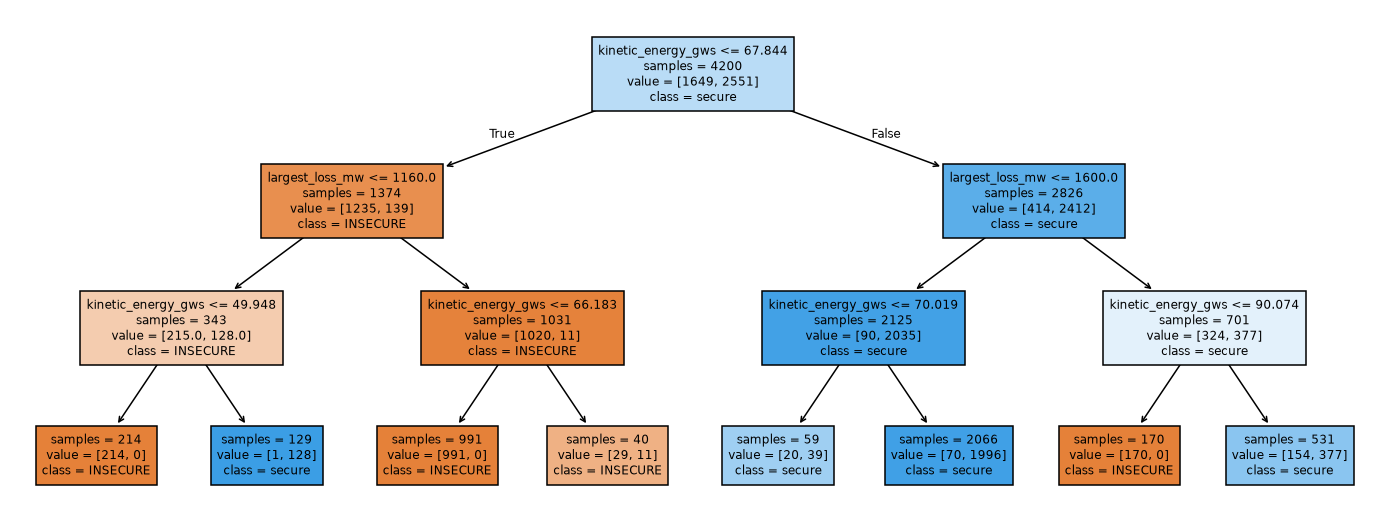

In [4]:
features = ["load_mw", "renewable_share", "H_s", "kinetic_energy_gws", "largest_loss_mw", "primary_reserve_mw", "ffr_mw"]
X, y = ops[features], ops.secure
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.3, random_state=0, stratify=y)
print(f"train: {len(X_tr)} operating points | test: {len(X_te)} operating points the models never see "
      f"(stratified, {1 - y_te.mean():.0%} insecure); all scores below are predictions on the test set")
tree = DecisionTreeClassifier(max_depth=3, min_samples_leaf=40, random_state=0).fit(X_tr, y_tr)
print(export_text(tree, feature_names=features, decimals=2))
fig, ax = plt.subplots(figsize=(16, 6))
plot_tree(tree, feature_names=features, class_names=["INSECURE", "secure"], filled=True, impurity=False, fontsize=8, ax=ax); plt.show()

**The tree rediscovered the physics.** Right after the trip, nothing but inertia opposes the power deficit, so
$\text{RoCoF}(0^+) = \dfrac{P_{loss}\,f_0}{2E_{kin}} \le 0.5\ \text{Hz/s} \;\Leftrightarrow\; E_{kin} \ge 50\,P_{loss}$ [MWs].
For losses of 1000, 1320, 1400 and 1800 MW this gives 50, 66, 70 and 90 GWs: the kinetic-energy thresholds the tree
learned from data alone (49.95, 66.18, 70.02, 90.07). A rule an operator can check is a rule an operator can trust.

## 4. Evaluating the classifier: confusion matrix and the cost of mistakes
We call the **alarm** (insecure) the *positive* class, so the words match control-room language:
* **false positive** = false alarm (predicted insecure, actually secure) → unnecessary but harmless re-dispatch cost;
* **false negative** = **missed alarm** (predicted secure, actually insecure) → no warning before a possible blackout.

$$\text{Accuracy}=\frac{TP+TN}{TP+TN+FP+FN},\qquad \text{Recall (alarms caught)}=\frac{TP}{TP+FN}$$

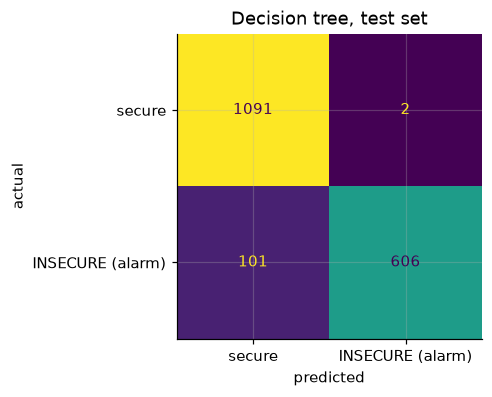

In [5]:
def evaluate(model, name, threshold=0.5):
    p_insecure = model.predict_proba(X_te)[:, 0]
    pred_alarm = (p_insecure >= threshold).astype(int)
    true_alarm = 1 - y_te.values
    tn, fp, fn, tp = confusion_matrix(true_alarm, pred_alarm, labels=[0, 1]).ravel()
    return {"model": name, "accuracy": accuracy_score(true_alarm, pred_alarm), "alarms caught (recall)": recall_score(true_alarm, pred_alarm),
            "missed alarms (FN)": fn, "false alarms (FP)": fp}, pred_alarm

r_tree, pred_tree = evaluate(tree, "decision tree (depth 3)")
fig, ax = plt.subplots(figsize=(4.2, 3.6))
ConfusionMatrixDisplay(confusion_matrix(1 - y_te, pred_tree), display_labels=["secure", "INSECURE (alarm)"]).plot(ax=ax, colorbar=False)
ax.set(title="Decision tree, test set", xlabel="predicted", ylabel="actual"); plt.show()

### Eliminating missed alarms
The two errors are not equally bad, so we bias the model: weight insecure cases 20× during training and raise the alarm
whenever the predicted insecurity probability exceeds a low threshold.

,accuracy,alarms caught (recall),missed alarms (FN),false alarms (FP)
model,,,,
decision tree (depth 3),94.3%,85.7%,101,2
decision tree (depth 6),96.2%,94.1%,42,27
"tree depth 6, insecure weighted ×20",92.2%,98.7%,9,132
random forest (300 trees),97.8%,95.2%,34,6
"random forest, alarm if P(insecure) > 0.1",85.7%,100.0%,0,258


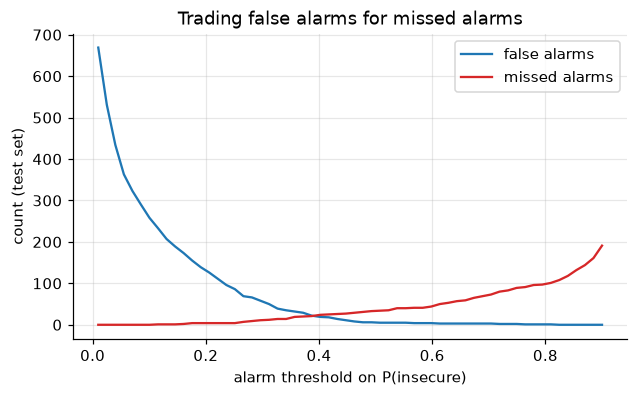

In [6]:
deep = DecisionTreeClassifier(max_depth=6, min_samples_leaf=20, random_state=0).fit(X_tr, y_tr)
safe = DecisionTreeClassifier(max_depth=6, min_samples_leaf=20, class_weight={0: 20, 1: 1}, random_state=0).fit(X_tr, y_tr)
forest = RandomForestClassifier(n_estimators=300, min_samples_leaf=3, n_jobs=-1, random_state=0).fit(X_tr, y_tr)
rows = [r_tree, evaluate(deep, "decision tree (depth 6)")[0], evaluate(safe, "tree depth 6, insecure weighted ×20")[0],
        evaluate(forest, "random forest (300 trees)")[0], evaluate(forest, "random forest, alarm if P(insecure) > 0.1", 0.1)[0]]
display(pd.DataFrame(rows).set_index("model").style.format({"accuracy": "{:.1%}", "alarms caught (recall)": "{:.1%}"}))

ths = np.linspace(0.01, 0.9, 60)
p_ins = forest.predict_proba(X_te)[:, 0]; true_alarm = 1 - y_te.values
fa = [((p_ins >= t) & (true_alarm == 0)).sum() for t in ths]; ma = [((p_ins < t) & (true_alarm == 1)).sum() for t in ths]
fig, ax = plt.subplots(figsize=(6.5, 3.6))
ax.plot(ths, fa, label="false alarms"); ax.plot(ths, ma, label="missed alarms", color="tab:red")
ax.set(xlabel="alarm threshold on P(insecure)", ylabel="count (test set)", title="Trading false alarms for missed alarms"); ax.legend(); plt.show()

Lowering the threshold removes missed alarms at the price of more false alarms. For safety-critical security assessment
that is the right trade: a false alarm costs a re-dispatch, a missed alarm can cost a blackout.

## 5. Why bother: speed
Our single-bus model is so small that it can be vectorised (section 2). A real TSO simulates the full network with
detailed machine and converter models for every contingency, which takes seconds to minutes per case; the trained
classifier answers in microseconds regardless of how detailed the simulator was.

adaptive time-domain simulation: 80 ms per case | decision tree: 0.59 µs per case (×134,662 faster)


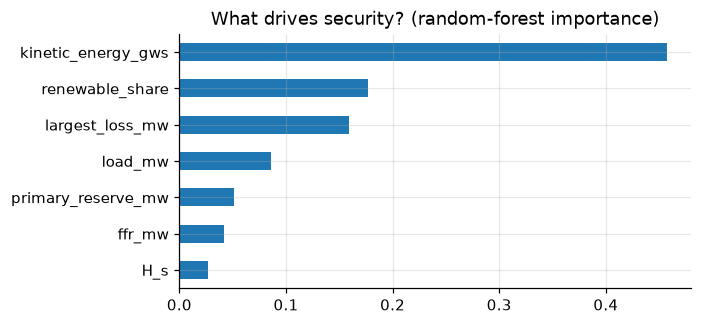

In [7]:
t0 = time.perf_counter()
for _ in range(100): tree.predict(X_te)
t_tree = (time.perf_counter() - t0) / 100 / len(X_te)
print(f"adaptive time-domain simulation: {1000 * sim_time:.0f} ms per case | decision tree: {1e6 * t_tree:.2f} µs per case "
      f"(×{sim_time / t_tree:,.0f} faster)")
imp = pd.Series(forest.feature_importances_, index=features).sort_values()
imp.plot.barh(figsize=(6, 3), title="What drives security? (random-forest importance)"); plt.show()

## Key takeaways
* DSA with ML = offline simulation database → classifier → real-time screening (thousands of times faster).
* Shallow decision trees give rules operators can read and verify (e.g. "kinetic energy below X GWs and loss above Y MW
  → insecure"); deeper trees and forests are more accurate but less transparent.
* Define the alarm as the positive class and tune for **zero missed alarms**; accept extra false alarms.
* The labels are only as good as the simulator: here an aggregated single-bus model, real DSA uses full dynamic
  models (PowerFactory, DSATools) and many contingencies.